# Lecture 9: Attention and Transformers

1. **Attention from scratch.** Write scaled dot-product attention, check that self-attention is permutation equivariant, then add position codes and check again.
2. **A vision transformer on BubbleML.** Train a small ViT on the 64 × 64 BubbleML data, compare it with the SmallCNN, and look at what its attention heads attend to.

In [1]:
import os
import time
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import torch
import torch.nn as nn
import torch.nn.functional as F

device = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
torch.manual_seed(0)

DATA_DIR = "../data/bubbleml"
FILE = "bubbleml2_Twall106_128.npz"
URL = "https://raw.githubusercontent.com/eecs-ml4sci/eecs-ml4sci.github.io/main/data/bubbleml/"
os.makedirs(DATA_DIR, exist_ok=True)
if not os.path.exists(os.path.join(DATA_DIR, FILE)):
    print("downloading", FILE)
    urllib.request.urlretrieve(URL + FILE, os.path.join(DATA_DIR, FILE))

# temperature colormap from Lecture 1 (https://github.com/therml-ai/boiling-viz), for theta in [0, 1]
temp_cmap = LinearSegmentedColormap.from_list("temp_green", list(zip(
    [0.0, 0.02, 0.04, 0.06, 0.08, 0.1, 0.134, 0.167, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
    ["#0000FF", "#0443FF", "#0E7AFF", "#16B4FF", "#1FF1FF", "#21FFD3", "#22FF9B", "#22FF67", "#22FF15", "#29FF06",
     "#45FF07", "#6DFF08", "#9EFF09", "#D4FF0A", "#FEF30A", "#FEB709", "#FD7D08", "#FC4908", "#FC1407", "#FB0007"])))

Using device: cpu


---
## Part 1: Attention from scratch

For $N$ tokens stacked as the rows of $X \in \mathbb{R}^{N \times d}$, self-attention computes

$$Q = XW_Q,\quad K = XW_K,\quad V = XW_V,\qquad \mathrm{Attention}(Q,K,V) = \mathrm{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V.$$

The softmax acts on each row, so the weights of each query sum to 1.

In [2]:
def attention(Q, K, V, mask=None):
    # Q: [..., N, dk], K: [..., N, dk], V: [..., N, dv]. Returns the outputs and the weights [..., N, N]
    scores = Q @ K.transpose(-2, -1) / Q.shape[-1] ** 0.5
    if mask is not None:
        scores = scores.masked_fill(~mask, float("-inf"))
    weights = torch.softmax(scores, dim=-1)
    return weights @ V, weights

# the worked example from the slides: three inputs, query q = (2, 0)
q = torch.tensor([[2.0, 0.0]])
K = torch.tensor([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]])
V = torch.tensor([[1.0, 0.0], [0.0, 2.0], [3.0, 3.0]])
o, w = attention(q, K, V)
print("weights:", w.numpy().round(3), "  output:", o.numpy().round(2))

weights: [[0.446 0.108 0.446]]   output: [[1.78 1.55]]


### Permutation equivariance

Recall Lecture 5: $f$ is equivariant to $g$ if $f(gx) = g f(x)$. Here $g$ reorders the tokens with a permutation matrix $P$.

In [3]:
torch.manual_seed(0)
N, d = 16, 32
X = torch.randn(N, d)
Wq, Wk, Wv = [torch.randn(d, d) / d ** 0.5 for _ in range(3)]

def self_attention(X):
    return attention(X @ Wq, X @ Wk, X @ Wv)[0]

perm = torch.randperm(N)
print("max |SA(PX) - P SA(X)|        :", (self_attention(X[perm]) - self_attention(X)[perm]).abs().max().item())

E = torch.randn(N, d)          # one position code per position; stays in place when the tokens move
print("with position codes, max diff  :", (self_attention(X[perm] + E) - self_attention(X + E)[perm]).abs().max().item())

max |SA(PX) - P SA(X)|        : 2.384185791015625e-07
with position codes, max diff  : 3.2161641120910645


**What to observe**

* Without position codes the difference is round-off: the outputs are the same vectors, reordered.
* With position codes the difference is as large as the outputs. The model can now tell where each token is.
* Mask a few entries with a causal mask, `mask = torch.ones(N, N).tril().bool()`. Is the layer still permutation equivariant?

---
## Part 2: A vision transformer on BubbleML

### The data

BubbleML_2, subcooled pool boiling of FC-72 with a 106 °C heater (the file of Lectures 6–8), averaged to 64 × 64.
Frames are 0.2 nondimensional time units apart. Channels: $\theta = (T - 50\,°\mathrm{C})/(106\,°\mathrm{C} - 50\,°\mathrm{C})$ and the velocity $u, v$.
The first 600 frames are for training and the last 201 for testing.

In [4]:
d = np.load(os.path.join(DATA_DIR, FILE))
data = np.stack([d["temperature"], d["velx"], d["vely"]], axis=1).astype(np.float32)   # [frames, 3, 128, 128]
data = data.reshape(len(data), 3, 64, 2, 64, 2).mean(axis=(3, 5))                       # 2 x 2 average -> 64 x 64
train_np, test_np = data[:600], data[600:]
mu, sd = train_np.mean(axis=(0, 2, 3)), train_np.std(axis=(0, 2, 3))
du = train_np[1:] - train_np[:-1]
mu_du, sd_du = du.mean(axis=(0, 2, 3)), du.std(axis=(0, 2, 3))
train_t = torch.from_numpy(train_np)
print("train:", train_np.shape, "  test:", test_np.shape)

train: (600, 3, 64, 64)   test: (201, 3, 64, 64)


### Two models

Both predict the standardized change of $\theta, u, v$ over one frame (Lecture 4), as in the Lecture 7 notebook.

* **`SmallCNN`**: four 3 × 3 convolutions, 32 channels.
* **`ViT`**: patches of 4 × 4 cells, so a 64 × 64 frame gives $N = 256$ tokens. Patch embedding (a convolution with kernel 4 and stride 4) to dimension $d = 64$, a learned position code, 4 pre-norm transformer blocks with 4 heads, and a linear layer that maps each token back to a 4 × 4 patch of the three fields. Every patch attends to every patch.
* **`ViT-local`**: the same ViT with neighborhood attention: each patch attends only to the 5 × 5 patches around it (`radius=2`).

In [5]:
class Attention(nn.Module):
    def __init__(self, d, heads):
        super().__init__()
        self.h = heads
        self.qkv = nn.Linear(d, 3 * d)
        self.out = nn.Linear(d, d)
        self.weights = None                        # attention weights of the last call, for plotting

    def forward(self, x, mask=None):               # x: [B, N, d]
        B, N, D = x.shape
        q, k, v = self.qkv(x).view(B, N, 3, self.h, D // self.h).permute(2, 0, 3, 1, 4)   # each [B, h, N, d/h]
        o, w = attention(q, k, v, mask)
        self.weights = w.detach()
        return self.out(o.transpose(1, 2).reshape(B, N, D))

class Block(nn.Module):
    def __init__(self, d, heads):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.attn = Attention(d, heads)
        self.mlp = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))

    def forward(self, x, mask=None):
        x = x + self.attn(self.ln1(x), mask)       # Z = X + MHA(LN(X))
        return x + self.mlp(self.ln2(x))           # Y = Z + MLP(LN(Z))

class ViTBody(nn.Module):
    def __init__(self, c=3, n=64, p=4, d=64, depth=4, heads=4, radius=None):
        super().__init__()
        self.p, self.g = p, n // p                 # patch size, patches per side
        mask = None
        if radius is not None:                     # neighborhood attention: patches within `radius` in each direction
            yy, xx = torch.meshgrid(torch.arange(self.g), torch.arange(self.g), indexing="ij")
            yy, xx = yy.flatten(), xx.flatten()
            mask = ((yy[:, None] - yy[None]).abs() <= radius) & ((xx[:, None] - xx[None]).abs() <= radius)
        self.register_buffer("mask", mask, persistent=False)
        self.embed = nn.Conv2d(c, d, p, stride=p)  # patch embedding
        self.pos = nn.Parameter(0.02 * torch.randn(1, self.g ** 2, d))
        self.blocks = nn.ModuleList([Block(d, heads) for _ in range(depth)])
        self.ln = nn.LayerNorm(d)
        self.head = nn.Linear(d, c * p * p)        # each token -> one p x p patch of c fields

    def forward(self, x):
        B, c = x.shape[0], x.shape[1]
        t = self.embed(x).flatten(2).transpose(1, 2) + self.pos            # [B, N, d]
        for blk in self.blocks:
            t = blk(t, self.mask)
        y = self.head(self.ln(t))                                           # [B, N, c p p]
        y = y.view(B, self.g, self.g, c, self.p, self.p).permute(0, 3, 1, 4, 2, 5)
        return y.reshape(B, c, self.g * self.p, self.g * self.p)

def smallcnn_body(cin=3, hidden=32, cout=3):
    cv = lambda i, o: nn.Conv2d(i, o, 3, padding=1)
    return nn.Sequential(cv(cin, hidden), nn.GELU(), cv(hidden, hidden), nn.GELU(), cv(hidden, hidden), nn.GELU(), cv(hidden, cout))

class Surrogate(nn.Module):
    def __init__(self, body):
        super().__init__()
        self.net = body
        self.register_buffer("mu", torch.tensor(mu).view(1, 3, 1, 1))
        self.register_buffer("sd", torch.tensor(sd).view(1, 3, 1, 1))
        self.register_buffer("mu_du", torch.tensor(mu_du).view(1, 3, 1, 1))
        self.register_buffer("sd_du", torch.tensor(sd_du).view(1, 3, 1, 1))

    def increment(self, x):                        # standardized change, the network's output
        return self.net((x - self.mu) / self.sd)

    def forward(self, x):                          # next state
        return x + self.mu_du + self.sd_du * self.increment(x)

for name, body in [("SmallCNN", smallcnn_body()), ("ViT", ViTBody())]:
    print(f"{name:8s} parameters: {sum(p.numel() for p in body.parameters()):,}")

SmallCNN parameters: 20,259
ViT      parameters: 222,704


### Trained models

All three models were trained with one-step training for 4000 optimizer steps, batch 16. The ViTs use a smaller learning rate and a short warm-up, which transformers usually need.
With `TRAIN = False` the notebook loads these trained weights. Set `TRAIN = True` to train them yourself: about 10 to 25 minutes per model on a laptop CPU, faster on a GPU.

In [6]:
TRAIN = False
STEPS = 4000
CKPT_DIR = "../data/lecture09"
CKPT_URL = "https://raw.githubusercontent.com/eecs-ml4sci/eecs-ml4sci.github.io/main/data/lecture09/"

def train(body, lr, steps=STEPS, batch=16, warmup=50, seed=0):
    torch.manual_seed(seed); g = np.random.default_rng(seed)
    model = Surrogate(body).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1, (s + 1) / warmup) * 0.5 * (1 + np.cos(np.pi * s / steps)))
    t0 = time.time()
    for step in range(steps):
        i = g.integers(0, len(train_t) - 1, batch)
        x, y = train_t[i].to(device), train_t[i + 1].to(device)
        loss = F.mse_loss(model.increment(x), (y - x - model.mu_du) / model.sd_du)
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        if step % 200 == 0 or step == steps - 1:
            print(f"  step {step:4d}  loss {loss.item():.3f}  ({time.time() - t0:.0f} s)")
    return model.eval()

def load(body, name):
    path = os.path.join(CKPT_DIR, name)
    if not os.path.exists(path):
        os.makedirs(CKPT_DIR, exist_ok=True)
        print("downloading", name); urllib.request.urlretrieve(CKPT_URL + name, path)
    body.load_state_dict(torch.load(path, map_location="cpu"))
    return Surrogate(body).to(device).eval()

specs = {"SmallCNN": (smallcnn_body, 1e-3, "smallcnn_4000.pt"),
         "ViT": (ViTBody, 5e-4, "vit_4000.pt"),
         "ViT-local": (lambda: ViTBody(radius=2), 5e-4, "vit_local_4000.pt")}
models = {}
for name, (make, lr, ckpt) in specs.items():
    torch.manual_seed(0)
    if TRAIN:
        print(name); models[name] = train(make(), lr=lr)
    else:
        models[name] = load(make(), ckpt)
m_cnn, m_vit, m_loc = models["SmallCNN"], models["ViT"], models["ViT-local"]

SmallCNN  one-step relative L2 error of θ: 0.158


ViT       one-step relative L2 error of θ: 0.217


ViT-local one-step relative L2 error of θ: 0.222


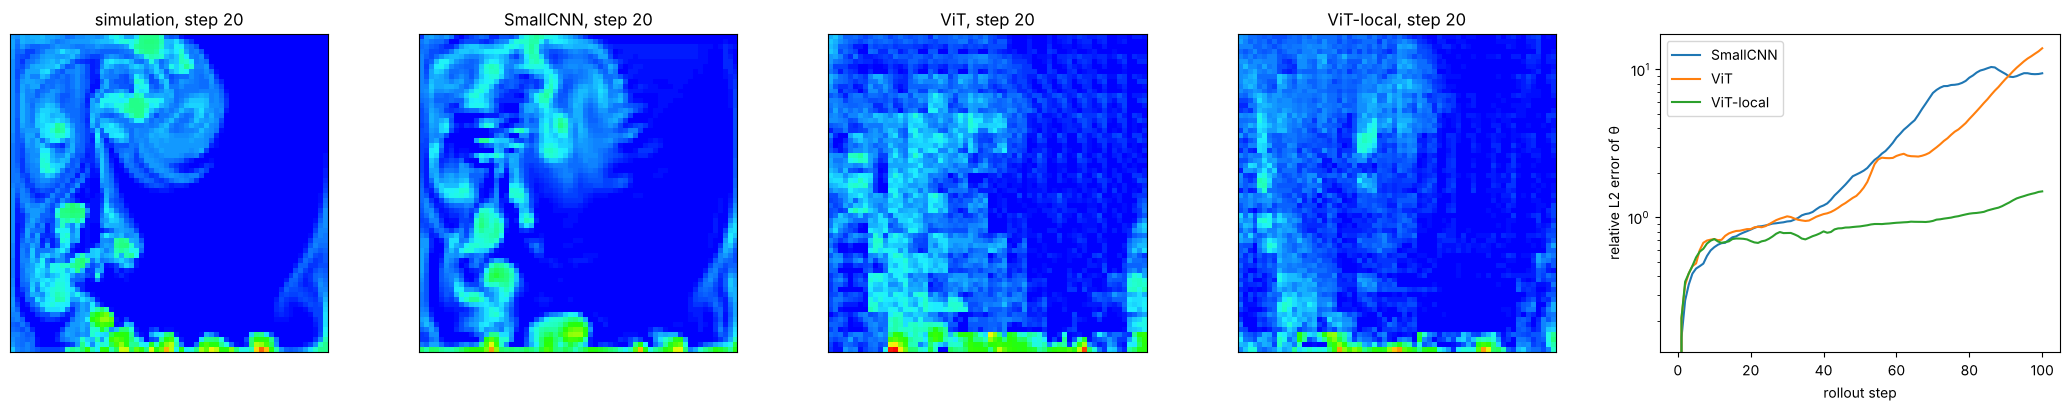

In [7]:
@torch.no_grad()
def one_step_error(model):
    x = torch.from_numpy(test_np[:-1]).to(device)
    p = torch.cat([model(x[i:i + 50]) for i in range(0, len(x), 50)]).cpu().numpy()[:, 0]
    t = test_np[1:, 0]
    return np.mean(np.linalg.norm((p - t).reshape(len(t), -1), axis=1) / np.linalg.norm(t.reshape(len(t), -1), axis=1))

@torch.no_grad()
def rollout(model, steps=100):
    s = torch.from_numpy(test_np[:1]).to(device); out = [test_np[0, 0]]
    for n in range(steps):
        s = model(s)
        out.append(s[0, 0].cpu().numpy())
    return np.stack(out)

def rel_err(roll):
    t = test_np[:len(roll), 0]
    return np.linalg.norm((roll - t).reshape(len(roll), -1), axis=1) / np.linalg.norm(t.reshape(len(roll), -1), axis=1)

for k, m in models.items():
    print(f"{k:9s} one-step relative L2 error of θ: {one_step_error(m):.3f}")
rolls = {k: rollout(m) for k, m in models.items()}

n = 20
fig, ax = plt.subplots(1, 5, figsize=(21, 4), layout="constrained")
for a, (f, t) in zip(ax[:4], [(test_np[n, 0], "simulation")] + [(rolls[k][n], k) for k in models]):
    a.imshow(f, cmap=temp_cmap, vmin=0, vmax=1, origin="lower"); a.set_title(f"{t}, step {n}"); a.set_xticks([]); a.set_yticks([])
for name, r in rolls.items():
    ax[4].semilogy(rel_err(r), label=name)
ax[4].set_xlabel("rollout step"); ax[4].set_ylabel("relative L2 error of θ"); ax[4].legend()
plt.show()

**What to observe**

* Compare the one-step errors. The SmallCNN, with a tenth of the parameters, is the most accurate. With 600 frames from one simulation, the CNN's built-in locality and translation equivariance help more than the ViT's flexibility (slide on data size).
* The neighborhood mask does not lower the one-step error of the ViT, but its rollout error grows more slowly. Restricting attention to nearby patches makes the model more stable when it is fed its own predictions.
* Look at the ViT predictions at step 20. The 4 × 4 patch grid is visible: each token is decoded into a whole patch, so detail smaller than a patch is hard to predict. This limits both ViTs; Exercise 2 changes the patch size.
* All rollouts drift (Lecture 7). The training methods of Lecture 7 (pushforward, noise) apply to the ViT unchanged.

### What does the ViT attend to?

Each attention layer stores its weights, an array `[batch, heads, N, N]`. Row $i$ is the weight that query patch $i$ puts on every key patch. Reshape a row to the 16 × 16 patch grid to see it as a map.

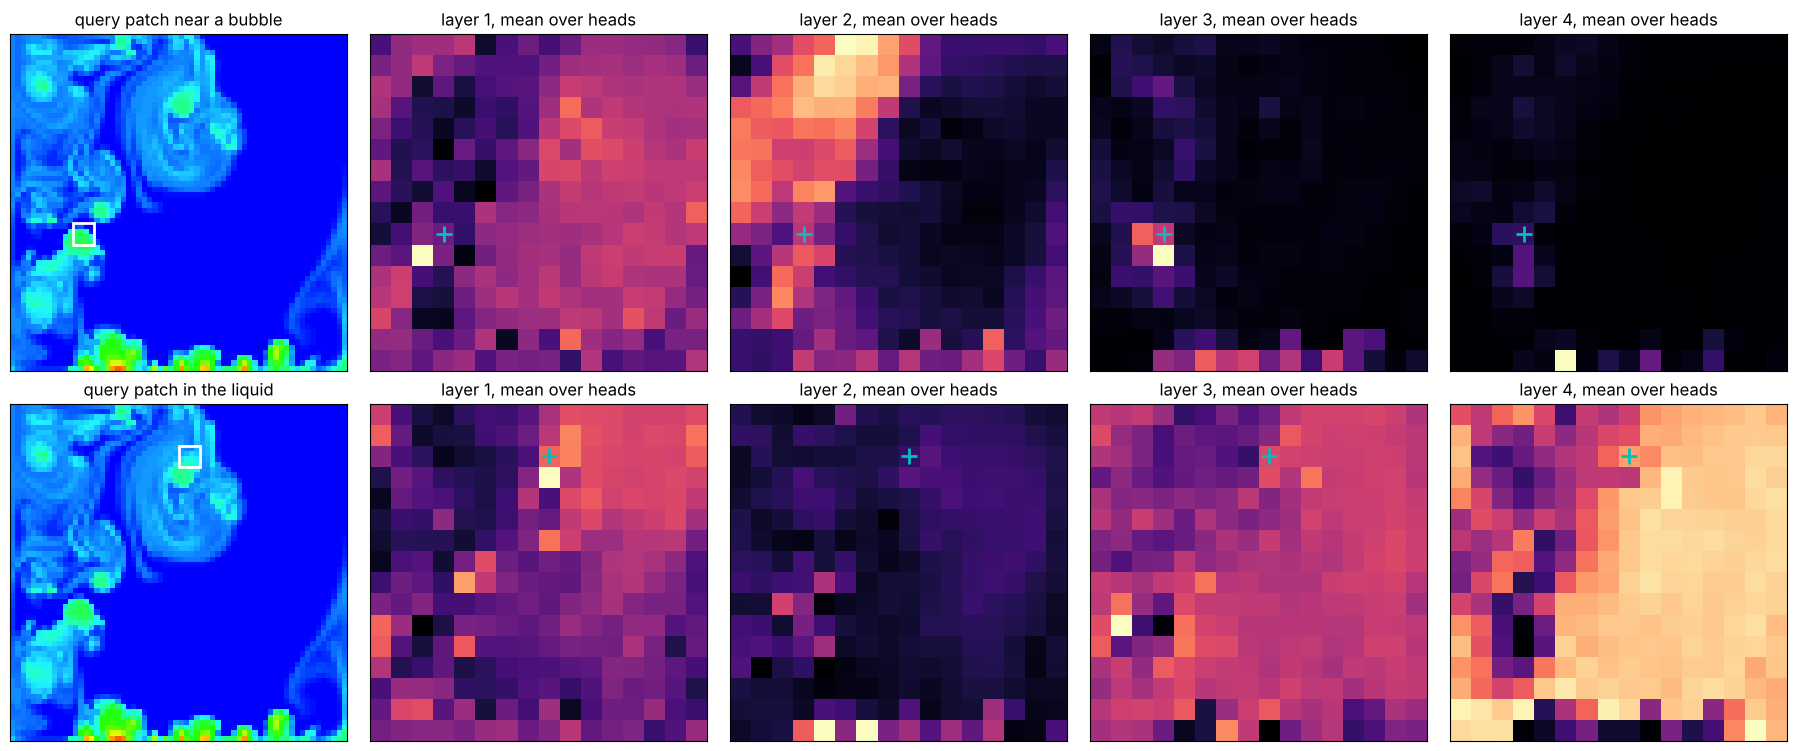

In [8]:
G = 16                                                         # patches per side
frame = 40
with torch.no_grad():
    m_vit(torch.from_numpy(test_np[frame:frame + 1]).to(device))
W = [blk.attn.weights[0].cpu().numpy() for blk in m_vit.net.blocks]   # per layer: [heads, N, N]

theta = test_np[frame, 0]
patch_theta = theta.reshape(G, 4, G, 4).mean(axis=(1, 3))
q_hot = int(np.argmax(patch_theta[3:, :].ravel())) + 3 * G     # hottest patch above the heater rows: near a bubble
q_liq = (G - 3) * G + G // 2                                   # a patch high in the liquid
fig, ax = plt.subplots(2, 5, figsize=(18, 7.4), layout="constrained")
for r, (q, name) in enumerate([(q_hot, "near a bubble"), (q_liq, "in the liquid")]):
    ax[r, 0].imshow(theta, cmap=temp_cmap, vmin=0, vmax=1, origin="lower")
    ax[r, 0].add_patch(plt.Rectangle(((q % G) * 4 - 0.5, (q // G) * 4 - 0.5), 4, 4, fill=False, ec="white", lw=2))
    ax[r, 0].set_title(f"query patch {name}")
    for l in range(4):
        a = W[l][:, q].mean(0).reshape(G, G)                  # average over heads
        ax[r, l + 1].imshow(a, origin="lower", cmap="magma")
        ax[r, l + 1].plot(q % G, q // G, "c+", ms=12, mew=2)
        ax[r, l + 1].set_title(f"layer {l + 1}, mean over heads")
for a in ax.ravel():
    a.set_xticks([]); a.set_yticks([])
plt.show()

### Mean attention distance

For each head, the distance from each query patch to the key patches, weighted by the attention weights, averaged over queries and test frames (the measure of the slide on trained models; distance in cells). Left: the global ViT. Right: ViT-local, whose distance is limited by the mask.

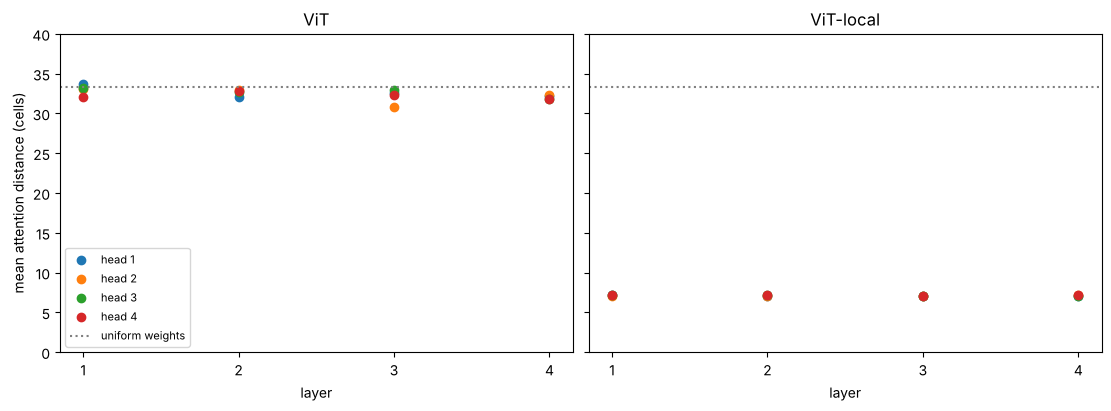

In [9]:
yy, xx = np.meshgrid(np.arange(G), np.arange(G), indexing="ij")
pos = np.stack([yy.ravel(), xx.ravel()], 1) * 4.0                  # patch centers, in cells
dist = np.linalg.norm(pos[:, None] - pos[None], axis=-1)          # [N, N]
def mean_attention_distance(model):
    with torch.no_grad():
        model(torch.from_numpy(test_np[0:200:10]).to(device))
    return np.array([(blk.attn.weights.cpu().numpy() * dist).sum(-1).mean(axis=(0, 2)) for blk in model.net.blocks])   # [layers, heads]

fig, ax = plt.subplots(1, 2, figsize=(11, 4), layout="constrained", sharey=True)
for a, (name, m) in zip(ax, [("ViT", m_vit), ("ViT-local", m_loc)]):
    mad = mean_attention_distance(m)
    for h in range(mad.shape[1]):
        a.plot(np.arange(1, len(mad) + 1), mad[:, h], "o", label=f"head {h + 1}")
    a.axhline(dist.mean(), color="gray", ls=":", label="uniform weights")
    a.set_xlabel("layer"); a.set_title(name); a.set_xticks(range(1, len(mad) + 1))
ax[0].set_ylabel("mean attention distance (cells)"); ax[0].legend(fontsize=8); ax[0].set_ylim(0, 40)
plt.show()

**What to observe**

* **Attention maps.** Each small image shows where one query patch (cyan +) looks: bright patches get more weight. Is the bright region a spot around the query, or spread over the frame?
* **Mean attention distance.** Each dot is one head: the average distance, in cells, from a query to the patches it attends to. The dotted line is the value for uniform attention over the whole frame. The global ViT stays near the line, so it has not learned that nearby patches matter more; 600 frames from one simulation are not enough. ViT-local is far below the line because the mask forces it. A CNN has locality built in, one reason the SmallCNN has the lowest one-step error.
* **Two queries.** Compare the maps for the patch near a bubble and the patch in the liquid. Different maps mean the weights depend on the input, which a convolution's fixed weights cannot do.

---
## Exercises

1. **Linear attention.** Write `galerkin_attention(Q, K, V)` that layer-normalizes K and V, skips the softmax, and returns $Q(\tilde K^\top \tilde V)/N$. Time it against `attention` for $N$ = 256, 1024, 4096 and 16384 with $d = 64$. Where does softmax attention run out of memory?
2. **Patch size.** Train `ViTBody(radius=2)` with patch size 2 (1024 tokens; scale the radius to 4 so it covers the same area) and 8 (64 tokens; radius 1). Compare the one-step error, the training time per step, and the energy spectrum of a prediction. Does a smaller patch close the gap to the SmallCNN?
3. **Attention over time.** Following Lecture 8, give the model temperature only as input. Stack the last 4 frames as 4 tokens per patch position, attend over those 4 tokens at each patch, then over space. Does it recover the gain of the ConvGRU?

In [10]:
# Exercise 1 starter
def galerkin_attention(Q, K, V):
    # TODO: layer-normalize K and V over the last dimension, then return Q @ (K^T V) / N
    raise NotImplementedError

def time_it(f, N, d=64, reps=3):
    Q, K, V = (torch.randn(1, N, d, device=device) for _ in range(3))
    f(Q, K, V)                                     # warm-up
    t0 = time.time()
    for _ in range(reps):
        f(Q, K, V)
    if device.type == "cuda":
        torch.cuda.synchronize()
    return (time.time() - t0) / reps

In [11]:
# Exercise 2 starter: a ViT with patch size 2 on the 64 x 64 frame (training is slower: 1024 tokens)
# m_p2 = train(ViTBody(p=2, radius=4), lr=5e-4)